<a href="https://colab.research.google.com/github/JJWest726/Jonathan_INFO4670_Fall2026/blob/main/Assignment3_AssociationRuleMining_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (11569 transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt


## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [11]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings as warn
warn.filterwarnings("ignore")
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
Bread = pd.read_csv("bread_basket.csv")

## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [12]:
Bread.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   transaction      20507 non-null  int64 
 1   item             20507 non-null  object
 2   date_time        20507 non-null  object
 3   time             20507 non-null  object
 4   period_day       20507 non-null  object
 5   weekday_weekend  20507 non-null  object
dtypes: int64(1), object(5)
memory usage: 961.4+ KB


### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [13]:
Bread.describe(include='all')

,transaction,item,date_time,time,period_day,weekday_weekend
count,20507.000000,20507,20507,20507,20507,20507
unique,NaN,94,159,1255,4,2
top,NaN,Coffee,2017-02-04,11:06,afternoon,weekday
freq,NaN,5471,292,52,11569,12807
mean,4976.202370,NaN,NaN,NaN,NaN,NaN
std,2796.203001,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN
25%,2552.000000,NaN,NaN,NaN,NaN,NaN
50%,5137.000000,NaN,NaN,NaN,NaN,NaN
75%,7357.000000,NaN,NaN,NaN,NaN,NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

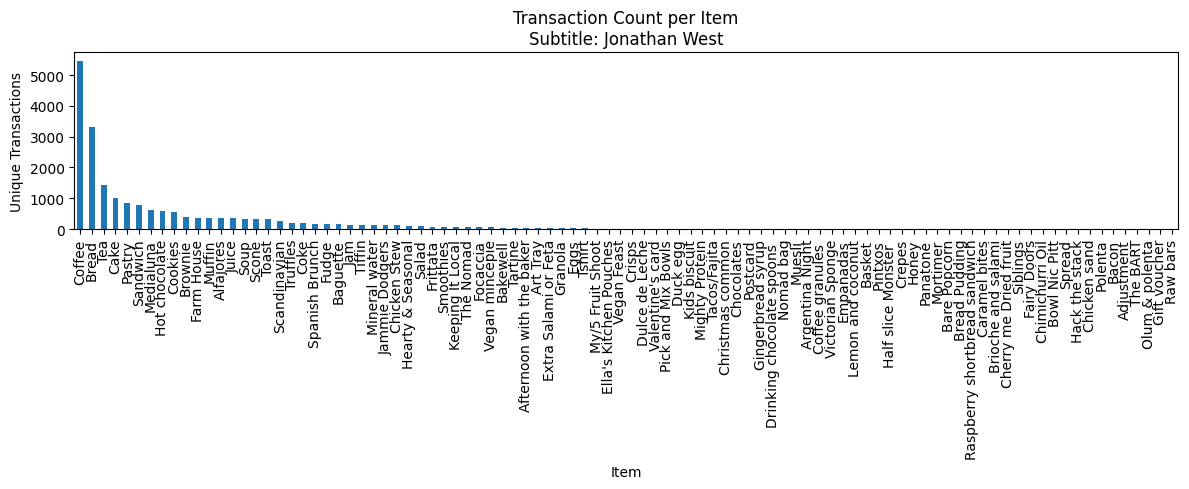

In [14]:
# c) Bar plot of transaction counts per item
subtitle = "Jonathan West"  # <-- EDIT THIS
item_counts = Bread["item"].value_counts() # <-- EDIT THIS
item_counts.sort_values(ascending=False)

ax = item_counts.plot(kind='bar', figsize=(12,5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item"); plt.ylabel("Unique Transactions")
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [15]:

print("The there were",int(Bread["item"].value_counts()["Coffee"]), "transactions that contained Coffee")
print("The there were",int(Bread["item"].value_counts()["Tea"]), "transactions that contained Tea")
print("The there were",int(Bread["item"].value_counts()["Alfajores"]), "transactions that contained Alfajores")
print("The there were",int(Bread["item"].value_counts()["Juice"]), "transactions that contained Juice")
print("The there were",int(Bread["item"].value_counts()["Chicken Stew"]), "transactions that contained Chicken Stew")


The there were 5471 transactions that contained Coffee
The there were 1435 transactions that contained Tea
The there were 369 transactions that contained Alfajores
The there were 369 transactions that contained Juice
The there were 123 transactions that contained Chicken Stew


## 3) Frequent Itemset Mining with FP‑Growth (min_support = 0.02) (20 pts)
We pivot the data to a **transaction × item** one‑hot table (boolean), then run FP‑Growth.

In [42]:
te = TransactionEncoder()
basket = (Bread.groupby('transaction')['item'].apply(list).reset_index().sort_values('transaction').head(20507)['item'].to_list())
te_ary = te.fit(basket).transform(basket)
One_Hot_table = pd.DataFrame(te_ary, columns=te.columns_).astype(bool)
freq_fp = fpgrowth(One_Hot_table, min_support=0.02, use_colnames=True)
rules_fp = association_rules(freq_fp, metric='confidence', min_threshold=0.02)
rules_fp[['antecedents','consequents','support','confidence','lift']].sort_values(['lift','confidence'], ascending=False)


,antecedents,consequents,support,confidence,lift
20,(Tea),(Cake),0.023772,0.166667,1.604781
21,(Cake),(Tea),0.023772,0.228891,1.604781
26,(Toast),(Coffee),0.023666,0.704403,1.472431
27,(Coffee),(Toast),0.023666,0.049470,1.472431
10,(Medialuna),(Coffee),0.035182,0.569231,1.189878
11,(Coffee),(Medialuna),0.035182,0.073542,1.189878
6,(Pastry),(Coffee),0.047544,0.552147,1.154168
7,(Coffee),(Pastry),0.047544,0.099382,1.154168
16,(Juice),(Coffee),0.020602,0.534247,1.116750
17,(Coffee),(Juice),0.020602,0.043065,1.116750


## 4) Association Rules + Report Table (30 pts)
(metric = confidence, min_threshold = ?) Please find a suitable min_threshold

In [46]:
freq_ap = apriori(One_Hot_table, min_support=0.01, use_colnames=True)
freq_ap.sort_values('support', ascending=False)
rules_ap = association_rules(freq_ap, metric='confidence', min_threshold=0.01)
rules_ap[['antecedents','consequents','support','confidence','lift']].sort_values(['lift','confidence'], ascending=False)

focus = {'Bread','Coffee','Cake'}
sub = rules_ap[
    rules_ap['antecedents'].apply(lambda s: s.issubset(focus)) &
    rules_ap['consequents'].apply(lambda s: s.issubset(focus))
].copy()

sub[['antecedents','consequents','support','confidence','lift']].sort_values(['lift','confidence'], ascending=False)


,antecedents,consequents,support,confidence,lift
24,(Cake),(Coffee),0.054728,0.526958,1.101515
25,(Coffee),(Cake),0.054728,0.114399,1.101515
58,"(Bread, Coffee)",(Cake),0.010037,0.111502,1.073621
59,(Cake),"(Bread, Coffee)",0.010037,0.096643,1.073621
56,"(Cake, Bread)",(Coffee),0.010037,0.429864,0.898557
61,(Coffee),"(Cake, Bread)",0.010037,0.020981,0.898557
7,(Bread),(Cake),0.023349,0.071359,0.687097
6,(Cake),(Bread),0.023349,0.224822,0.687097
8,(Bread),(Coffee),0.090016,0.275105,0.575059
9,(Coffee),(Bread),0.090016,0.188163,0.575059


## 5) Interpretation (10 pts)
**Interpret the rule `{Coffee, Cake} ⇒ {Bread}` in plain English.**

- **Support**: What fraction of *all* transactions contain Coffee, Cake, and Bread together?
- **Confidence**: Among baskets with Coffee and Cake, what share also include Bread?
- **Lift > 1** implies positive association; comment on practical meaning.

*Your notes:* The rule {Coffee, Cake} ⇒ {Bread} means how often is a purchase of both cake and coffee associated with a purchase of bread. Out of all transactions only 5.015% contain Cake Coffee and Bread. Among baskets with Coffee and Cake 18.34% contain bread. The lift among the baskets is less than one being .56 meaning that those who purchase Coffee and Cake purchase Bread less often than they statiscally should

>